### 1) import libraries & dataset load


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load titanic dataset directly from seaborn
df = sns.load_dataset('titanic')

# Display the first five rows
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### 2) Basic data exploration

In [3]:
# dataset information
df.info()
# statistical summary
df.describe()
# check missing values
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB
survived         0
pclass           0
sex              0
age            177
sib

In [5]:
# Fill missing age values with median
df['age'] = df['age'].fillna(df['age'].median())

# Fill missing embark_town values with mode
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])

# Check missing values again
print(df.isnull().sum())

survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      0
alive            0
alone            0
dtype: int64


### 1) Q1. Create a countplot to show the number of passengers by gender.

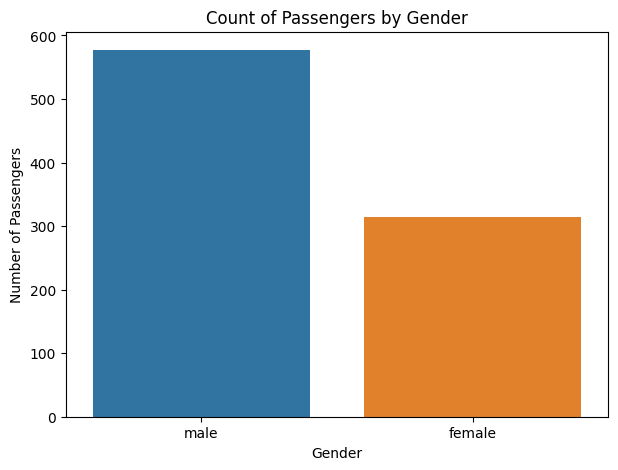

In [7]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='sex', hue='sex', legend=False)
plt.title('Count of Passengers by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Passengers')
plt.show()

### Q2)  Bar chart passengersby class

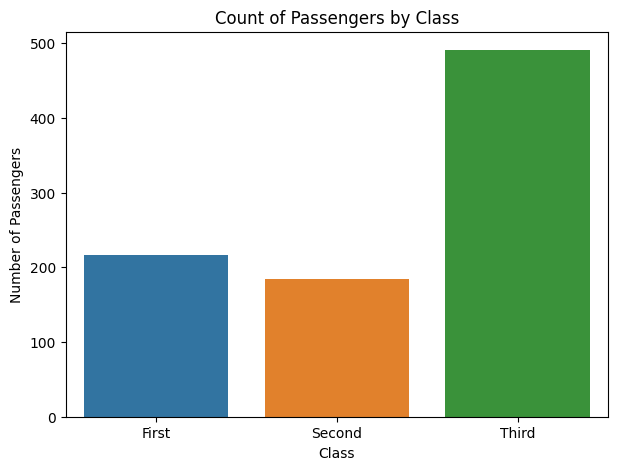

In [8]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='class', hue='class', legend=False)
plt.title('Count of Passengers by Class')
plt.xlabel('Class')
plt.ylabel('Number of Passengers')
plt.show()

### Q3) Histogram - distribution of passenger age

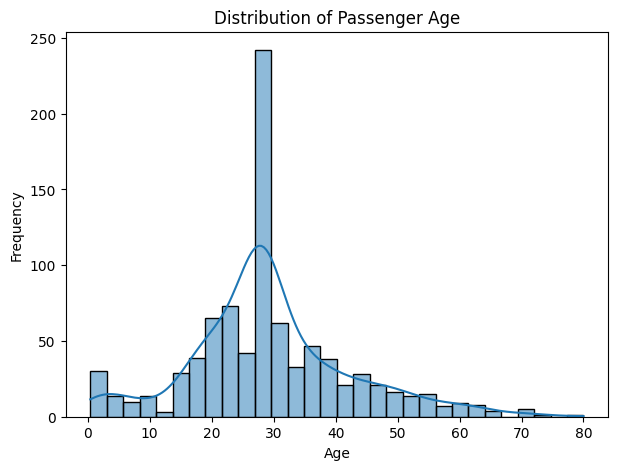

In [9]:
plt.figure(figsize=(7, 5))
sns.histplot(data=df, x='age', kde=True)
plt.title('Distribution of Passenger Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

### Q4) Boxplot - Detct outliers in fare

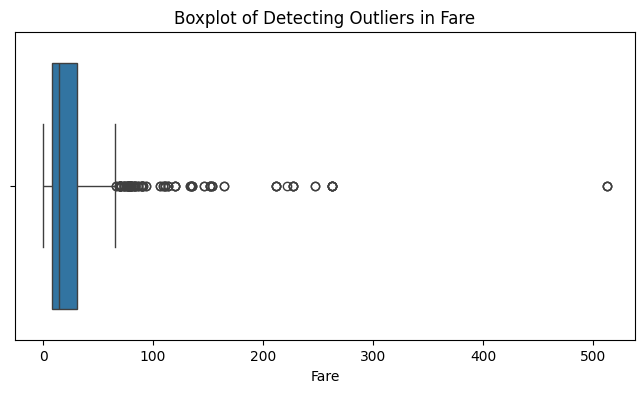

In [10]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='fare')
plt.title('Boxplot of Detecting Outliers in Fare')
plt.xlabel('Fare')
plt.show()
#

### Q5. Create a scatterplot to

 a. show the relationship between age and fare.

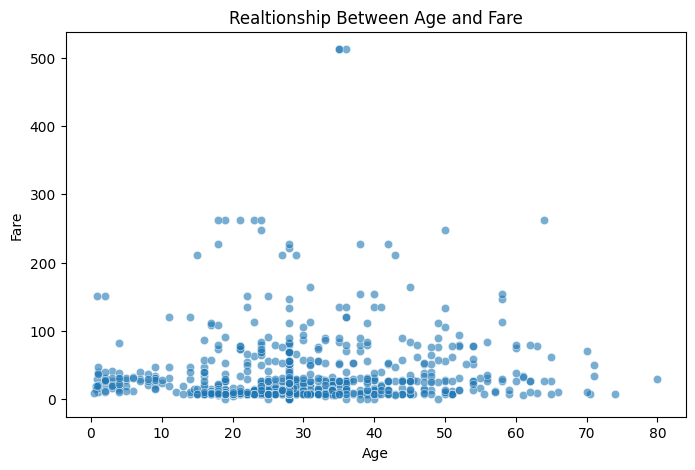

In [11]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='age', y='fare',alpha=0.6)
plt.title('Realtionship Between Age and Fare')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.show()
#

### Q5. Create a scatterplot to
b. analyze the relationship between family size (SibSp + Parch) and fare.

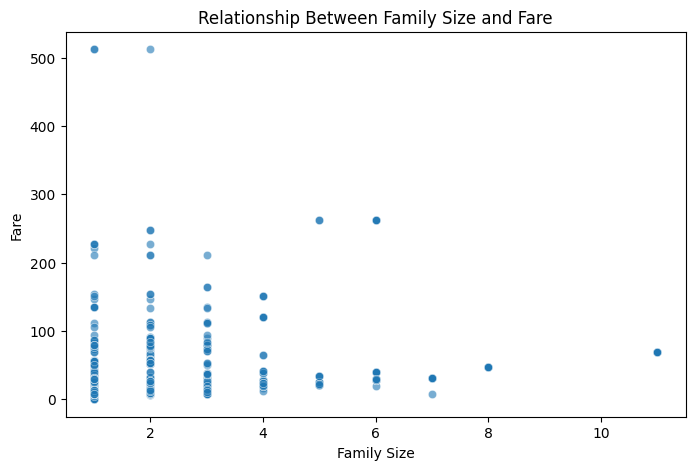

In [12]:
# Calculate family size
df['family_size'] = df['sibsp'] + df['parch']+1
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='family_size', y='fare',alpha=0.6)
plt.title('Relationship Between Family Size and Fare')
plt.xlabel('Family Size')
plt.ylabel('Fare')
plt.show()
#

### Q6. Create a countplot to show survival count by gender.

In [13]:
# print("--- Q6: Survival by Gender ---")
print(df.groupby('sex')['survived'].value_counts())

sex     survived
female  1           233
        0            81
male    0           468
        1           109
Name: count, dtype: int64


### Q7. Create a bar chart to show survival by passenger class

In [14]:
print("\n--- Q7: Survival by Class ---")
print(df.groupby('class')['survived'].value_counts())


--- Q7: Survival by Class ---
class   survived
First   1           136
        0            80
Second  0            97
        1            87
Third   0           372
        1           119
Name: count, dtype: int64


/tmp/ipykernel_3235/4243958497.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('class')['survived'].value_counts())


### Q8. Create a heatmap to show correlation between numerical variables.

In [15]:
print("\n--- Q8: Correlation Matrix ---")
numeric_df = df.select_dtypes(include=['number'])
print(numeric_df.corr())


--- Q8: Correlation Matrix ---
             survived    pclass       age     sibsp     parch      fare  \
survived     1.000000 -0.338481 -0.064910 -0.035322  0.081629  0.257307   
pclass      -0.338481  1.000000 -0.339898  0.083081  0.018443 -0.549500   
age         -0.064910 -0.339898  1.000000 -0.233296 -0.172482  0.096688   
sibsp       -0.035322  0.083081 -0.233296  1.000000  0.414838  0.159651   
parch        0.081629  0.018443 -0.172482  0.414838  1.000000  0.216225   
fare         0.257307 -0.549500  0.096688  0.159651  0.216225  1.000000   
family_size  0.016639  0.065997 -0.245619  0.890712  0.783111  0.217138   

             family_size  
survived        0.016639  
pclass          0.065997  
age            -0.245619  
sibsp           0.890712  
parch           0.783111  
fare            0.217138  
family_size     1.000000  


### Q9. Identify which passenger class paid the highest fare on average.


In [16]:
print("\n--- Q9: Average Fare by Class ---")
print(df.groupby('class')['fare'].mean())


--- Q9: Average Fare by Class ---
class
First     84.154687
Second    20.662183
Third     13.675550
Name: fare, dtype: float64


/tmp/ipykernel_3235/1465531180.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('class')['fare'].mean())


### Q10. Write at least 5 insights from the dataset based on your visualizations.

1) Gender-Based Survival Disparity (Q6): Female passengers had a significantly higher survival count and survival rate compared to male passengers, aligning with the "women and children first" maritime evacuation protocol.

2) Socio-Economic Impact on Survival (Q7): Passengers in First Class experienced much higher survival counts and proportions than those in Third Class, reflecting preferential access to lifeboats and upper-deck exits.

3) Class Cost Hierarchy (Q9): First Class tickets cost considerably more on average than Second and Third class tickets, confirming a strong tiered pricing system based on accommodations.

4) Age and Fare Distribution (Q3 & Q4): The fare column is heavily right-skewed with notable high outliers (visible in boxplots), representing luxury suites bought by wealthy passengers.

5) Family Size and Fare Relationship (Q5): Passengers traveling with larger families (sibsp + parch) generally incurred higher total ticket costs or occupied group bookings, showing correlation between family count and overall ticket expenses on the correlation heatmap (Q8).